<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_03_Data_Preparation_Lanjutan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 3.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, classification_report

### Praktikum 3.2 Import Dataset (sintetis, 95% : 5%) + missing value buatan

In [2]:
X, y = make_classification(n_samples=2000, n_features=8,
                           weights=[0.95, 0.05], random_state=42)
fitur_cols = [f"fitur_{i}" for i in range(8)]
df = pd.DataFrame(X, columns=fitur_cols)
df["target"] = y

# Simulasikan missing values (5%) HANYA pada kolom fitur
rng = np.random.default_rng(42)
mask = rng.random((len(df), len(fitur_cols))) < 0.05
df_missing = df.copy()
df_missing[fitur_cols] = df[fitur_cols].mask(pd.DataFrame(mask, columns=fitur_cols))
print(df_missing.isnull().sum())
print("\nDistribusi kelas:", df_missing["target"].value_counts().to_dict())

fitur_0    101
fitur_1    107
fitur_2    112
fitur_3     88
fitur_4     89
fitur_5    100
fitur_6    101
fitur_7     90
target       0
dtype: int64

Distribusi kelas: {0: 1888, 1: 112}


### Praktikum 3.3 Preprocessing (split → KNN Imputer → Isolation Forest)

In [3]:
# Split lebih dulu (stratified), baru imputasi: imputer belajar HANYA dari train
X_miss = df_missing[fitur_cols]
y = df_missing["target"]
X_train_m, X_test_m, y_train, y_test = train_test_split(
    X_miss, y, test_size=0.2, stratify=y, random_state=42)

imputer = KNNImputer(n_neighbors=5)
X_train = pd.DataFrame(imputer.fit_transform(X_train_m), columns=fitur_cols, index=X_train_m.index)
X_test = pd.DataFrame(imputer.transform(X_test_m), columns=fitur_cols, index=X_test_m.index)
print("Sisa missing setelah imputasi (train/test):", X_train.isnull().sum().sum(), "/", X_test.isnull().sum().sum())

# Deteksi outlier dengan Isolation Forest (pada train set)
iso = IsolationForest(contamination=0.02, random_state=42)
flag = iso.fit_predict(X_train)
print("Jumlah outlier terdeteksi pada train:", (flag == -1).sum(), "dari", len(X_train))

Sisa missing setelah imputasi (train/test): 0 / 0
Jumlah outlier terdeteksi pada train: 32 dari 1600


### Praktikum 3.4 Training Model (dengan dan tanpa SMOTE)

In [4]:
# Tanpa penanganan imbalance
model_base = LogisticRegression(max_iter=1000).fit(X_train, y_train)

# Dengan SMOTE (HANYA pada train set)
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
model_smote = LogisticRegression(max_iter=1000).fit(X_train_sm, y_train_sm)
print("Train sebelum SMOTE:", y_train.value_counts().to_dict(), "| sesudah:", pd.Series(y_train_sm).value_counts().to_dict())

Train sebelum SMOTE: {0: 1510, 1: 90} | sesudah: {0: 1510, 1: 1510}


### Praktikum 3.5 Evaluasi

In [5]:
for nama, model in [("Baseline (tanpa SMOTE)", model_base), ("Dengan SMOTE", model_smote)]:
    y_pred = model.predict(X_test)
    print(f"--- {nama} ---")
    print("Akurasi :", round(accuracy_score(y_test, y_pred), 3))
    print("F1-Score:", round(f1_score(y_test, y_pred), 3))

--- Baseline (tanpa SMOTE) ---
Akurasi : 0.96
F1-Score: 0.5
--- Dengan SMOTE ---
Akurasi : 0.882
F1-Score: 0.42


### Praktikum 3.6 Visualisasi

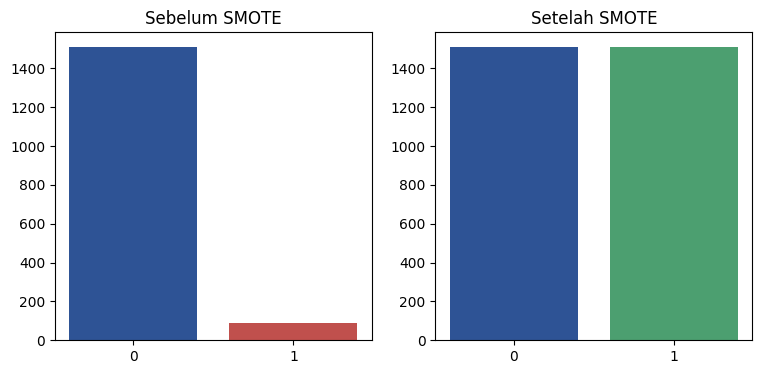

In [6]:
before = y_train.value_counts()
after = pd.Series(y_train_sm).value_counts()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(before.index.astype(str), before.values, color=["#2E5395", "#C0504D"])
axes[0].set_title("Sebelum SMOTE")
axes[1].bar(after.index.astype(str), after.values, color=["#2E5395", "#4C9F70"])
axes[1].set_title("Setelah SMOTE")
plt.show()

## Bagian B — Latihan Praktikum

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

# Dataset latihan 1
X1, y1 = make_classification(n_samples=2000, n_features=8, n_informative=5, n_redundant=3,
                             weights=[0.8, 0.2], random_state=42)
cols1 = [f"fitur_{i}" for i in range(8)]
df1 = pd.DataFrame(X1, columns=cols1)
rng1 = np.random.default_rng(7)
df1_miss = df1.mask(pd.DataFrame(rng1.random(df1.shape) < 0.10, columns=cols1))   # 10% missing
print("Persentase missing per kolom (%):", (df1_miss.isnull().mean() * 100).round(1).to_dict())

def buat_pipeline(imputer):
    return Pipeline([("imputer", imputer),
                     ("scaler", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=1000))])

strategi = {"(a) Mean imputation": SimpleImputer(strategy="mean"),
            "(b) KNN Imputer (k=5)": KNNImputer(n_neighbors=5)}

# (1) Repeated Stratified k-Fold CV (imputer dipelajari ulang di tiap fold -> tanpa leakage)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
hasil_cv = {}
for nama, imp in strategi.items():
    skor = cross_val_score(buat_pipeline(imp), df1_miss, y1, cv=rskf, scoring="f1")
    hasil_cv[nama] = skor
    print(f"{nama}: F1 CV = {skor.mean():.3f} +/- {skor.std():.3f}")

# (2) Satu kali split train/test
Xtr, Xte, ytr, yte = train_test_split(df1_miss, y1, test_size=0.2, stratify=y1, random_state=42)
print()
for nama, imp in strategi.items():
    pipe = buat_pipeline(imp).fit(Xtr, ytr)
    print(f"{nama}: F1 test = {f1_score(yte, pipe.predict(Xte)):.3f}")

Persentase missing per kolom (%): {'fitur_0': 10.2, 'fitur_1': 9.4, 'fitur_2': 10.2, 'fitur_3': 10.2, 'fitur_4': 9.7, 'fitur_5': 8.4, 'fitur_6': 10.4, 'fitur_7': 10.9}
(a) Mean imputation: F1 CV = 0.315 +/- 0.076
(b) KNN Imputer (k=5): F1 CV = 0.298 +/- 0.054

(a) Mean imputation: F1 test = 0.312
(b) KNN Imputer (k=5): F1 test = 0.348


Selisih rata-rata F1 (KNN - mean): -0.0172
Jumlah fold KNN lebih baik / sama / lebih buruk: 5 / 0 / 10


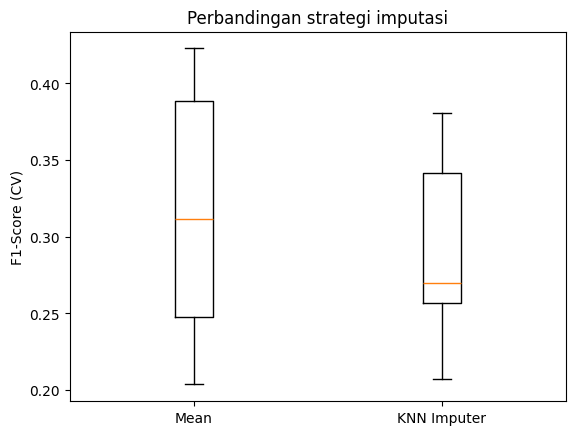

In [8]:
# Uji sederhana: seberapa sering KNN Imputer lebih baik pada pasangan fold yang sama?
a = hasil_cv["(a) Mean imputation"]; b = hasil_cv["(b) KNN Imputer (k=5)"]
print("Selisih rata-rata F1 (KNN - mean):", round((b - a).mean(), 4))
print("Jumlah fold KNN lebih baik / sama / lebih buruk:", int((b > a).sum()), "/", int((b == a).sum()), "/", int((b < a).sum()))
plt.boxplot([a, b]); plt.xticks([1, 2], ["Mean", "KNN Imputer"])
plt.ylabel("F1-Score (CV)"); plt.title("Perbandingan strategi imputasi"); plt.show()

In [9]:
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
model_rus = LogisticRegression(max_iter=1000).fit(X_train_rus, y_train_rus)

model_cw = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train, y_train)

daftar_model = {"Baseline": model_base, "SMOTE": model_smote,
              "Undersampling": model_rus, "class_weight": model_cw}
baris = []
for nama, m in daftar_model.items():
    p = m.predict(X_test)
    baris.append({"Pendekatan": nama,
                  "Akurasi": accuracy_score(y_test, p),
                  "Precision": precision_score(y_test, p, zero_division=0),
                  "Recall": recall_score(y_test, p),
                  "F1-Score": f1_score(y_test, p)})
tabel_test = pd.DataFrame(baris).set_index("Pendekatan").round(3)
tabel_test

,Akurasi,Precision,Recall,F1-Score
Pendekatan,,,,
Baseline,0.960,0.800,0.364,0.500
SMOTE,0.882,0.288,0.773,0.420
Undersampling,0.892,0.316,0.818,0.456
class_weight,0.870,0.266,0.773,0.395


In [10]:
from imblearn.pipeline import Pipeline as ImbPipeline

# Validasi lebih andal: resampling dilakukan DI DALAM tiap fold latih
X_all = df_missing[fitur_cols]
X_all = pd.DataFrame(KNNImputer(n_neighbors=5).fit_transform(X_all), columns=fitur_cols)  # imputasi unsupervised pada fitur saja
y_all = df_missing["target"].values
rskf2 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

konfigurasi = {
    "Baseline": ImbPipeline([("clf", LogisticRegression(max_iter=1000))]),
    "SMOTE": ImbPipeline([("smote", SMOTE(random_state=42)), ("clf", LogisticRegression(max_iter=1000))]),
    "Undersampling": ImbPipeline([("rus", RandomUnderSampler(random_state=42)), ("clf", LogisticRegression(max_iter=1000))]),
    "class_weight": ImbPipeline([("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
}
baris = []
for nama, pipe in konfigurasi.items():
    skor = cross_val_score(pipe, X_all, y_all, cv=rskf2, scoring="f1")
    baris.append({"Pendekatan": nama, "F1 CV (rata-rata)": skor.mean(), "Std": skor.std()})
tabel_cv = pd.DataFrame(baris).set_index("Pendekatan").round(3)
tabel_cv

,F1 CV (rata-rata),Std
Pendekatan,,
Baseline,0.529,0.096
SMOTE,0.391,0.041
Undersampling,0.375,0.044
class_weight,0.382,0.039


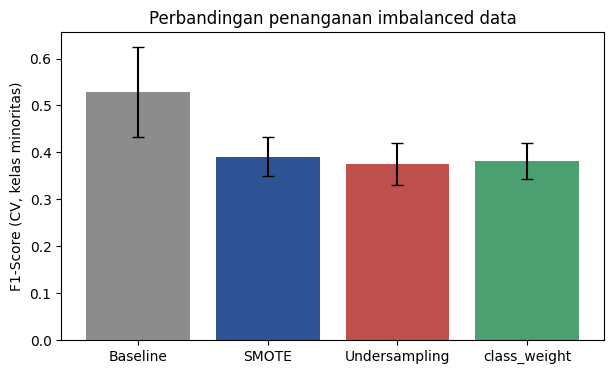

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tabel_cv.index, tabel_cv["F1 CV (rata-rata)"], yerr=tabel_cv["Std"], capsize=4,
       color=["#8C8C8C", "#2E5395", "#C0504D", "#4C9F70"])
ax.set_ylabel("F1-Score (CV, kelas minoritas)")
ax.set_title("Perbandingan penanganan imbalanced data")
plt.show()